In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from utils import display, stretch, shear, reflection, rotation, rotate_xy, rotate_xz, rotate_yz, read_off, plot_off, visualize_off

lynx = np.array([
[209.70, 368.42], [157.63, 332.16], [118.82, 284.21], [80.95, 224.56], [43.08, 244.44], [20.36, 266.67], [-4.26, 293.57], [2.37, 263.16], [-20.36, 292.40], [-39.29, 299.42], [-21.30, 259.65],
[-50.65, 267.84], [-39.29, 242.11], [-55.38, 240.94], [-100.83, 300.58], [-149.11, 345.03], [-172.78, 361.40], [-189.82, 300.58], [-192.66, 225.73], [-181.30, 145.03], [-168.05, 104.09], [-184.14, 66.67],
[-186.98, 31.58], [-183.20, 3.51], [-208.76, -4.68], [-197.40, -29.24], [-182.25, -44.44], [-203.08, -43.27], [-172.78, -92.40], [-131.12, -126.32], [-101.78, -147.37], [-74.32, -163.74], [-110.30, -224.56],
[-143.43, -287.72], [-161.42, -240.94], [-282.60, -221.05], [-388.64, -205.85], [-370.65, -301.75], [-339.41, -397.66], [18.46, -397.66], [345.09, -400.00], [359.29, -378.95], [367.81, -342.69], [346.98, -
362.57], [363.08, -302.92], [357.40, -243.27], [348.88, -266.67], [336.57, -201.17], [290.18, -135.67], [240.00, -118.13], [258.93, -164.91], [257.99, -228.07], [252.31, -271.35], [256.09, -333.33],
[247.57, -359.06], [230.53, -307.60], [194.56, -238.60], [160.47, -181.29], [120.71, -149.71], [165.21, -132.16], [201.18, -100.58], [183.20, -99.42], [221.07, -73.68], [253.25, -24.56], [222.01, -23.39],
[251.36, -1.17], [262.72, 24.56], [234.32, 25.73], [214.44, 42.11], [202.13, 60.82], [220.12, 101.75], [234.32, 160.23], [240.00, 230.41], [232.43, 316.96]
])

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


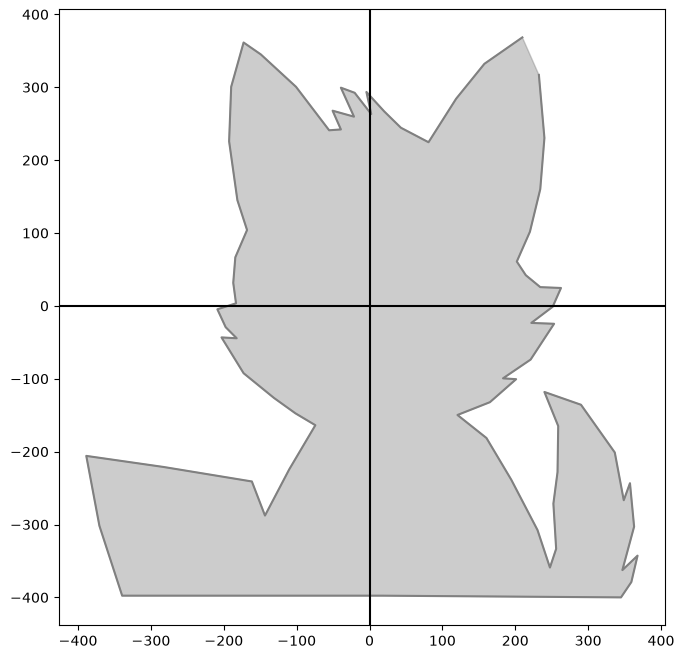

In [3]:
display(lynx, 'grey')

task 1


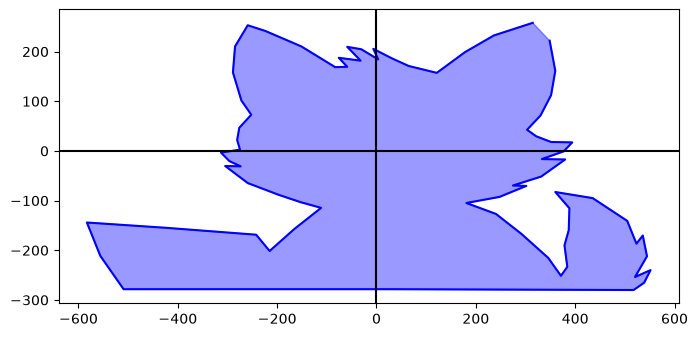

In [4]:
lynx_stretched, _ = stretch(lynx, 1.5, 0.7)
display(lynx_stretched, 'blue')

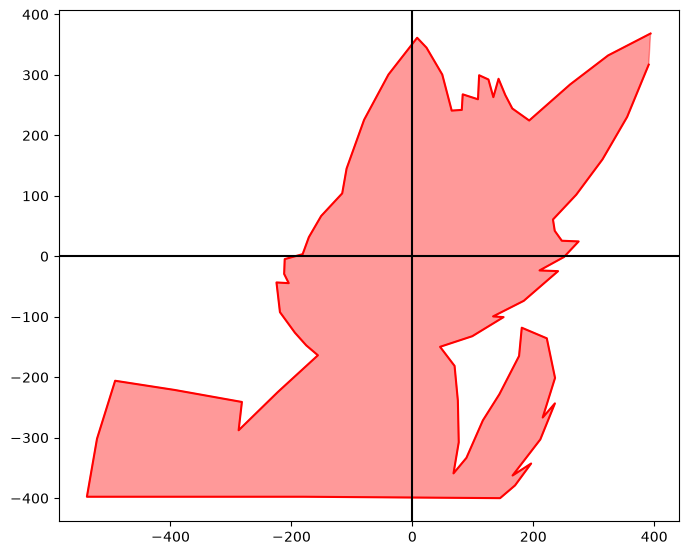

In [5]:
lynx_sheared, _ = shear(lynx, 0.5, 0)
display(lynx_sheared, 'red')

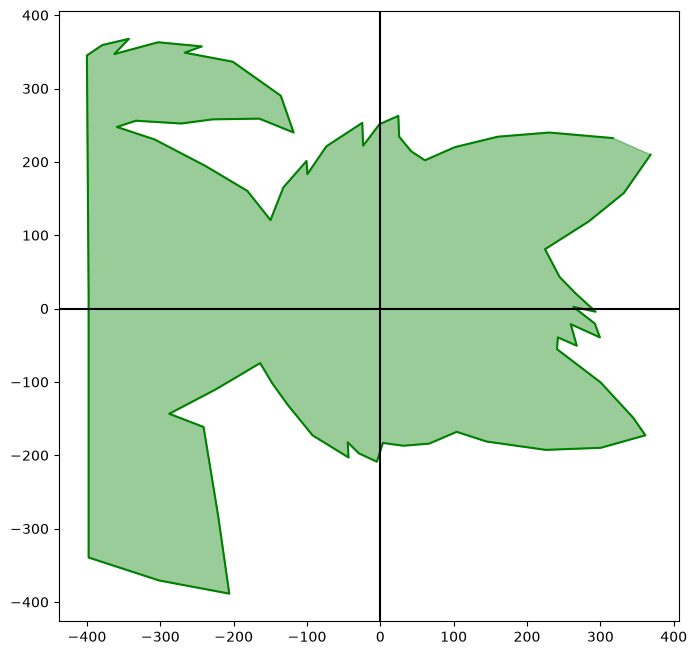

In [6]:
lynx_reflected, _ = reflection(lynx, 1, 1)
display(lynx_reflected, 'green')

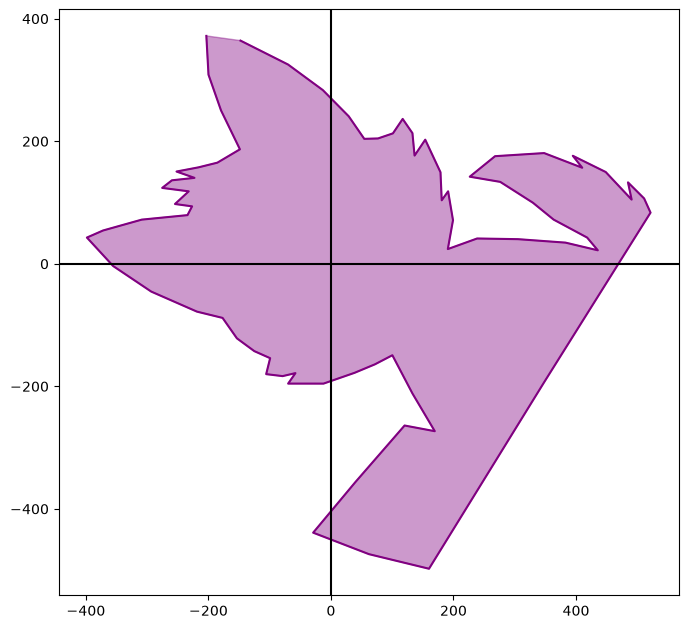

In [7]:
lynx_rotated, _ = rotation(lynx, 45)
display(lynx_rotated, 'purple')

task 2


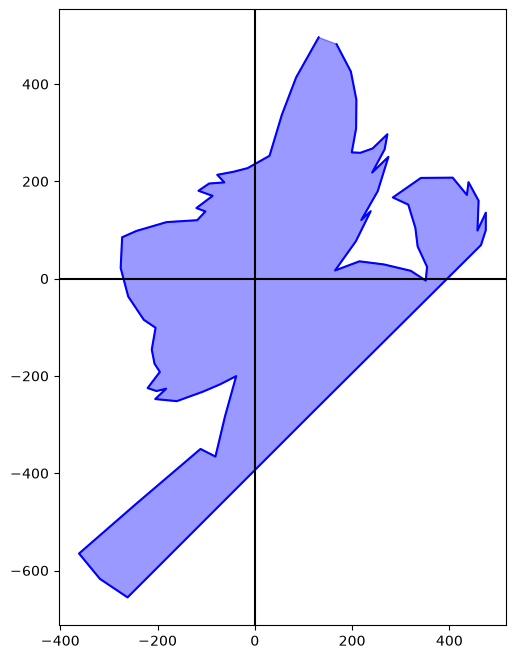

[[ 1.59099026 -0.53033009]
 [ 0.49497475  0.49497475]]


In [8]:
s_lynx, M_str = stretch(lynx, 1.5, 0.7)
sh_lynx, M_shr = shear(s_lynx, 0.5, 0)
lynx_combination1, M_rot = rotation(sh_lynx, np.pi / 4)

display(lynx_combination1)
print(M_str @ M_shr @ M_rot)


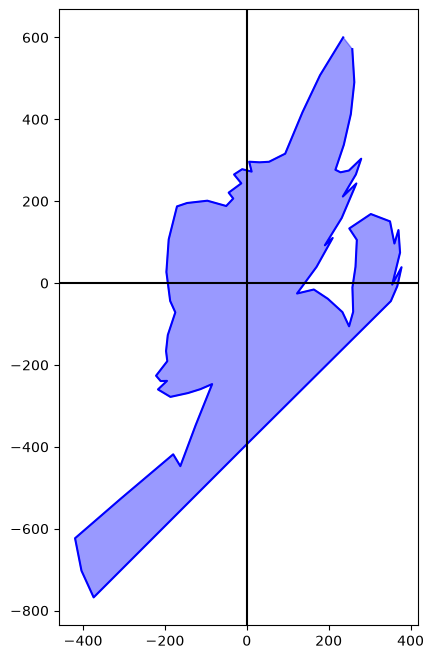

[[ 1.30814755 -0.8131728 ]
 [ 0.49497475  0.49497475]]


In [9]:
sh_lynx, M_shr = shear(lynx, 0.5, 0)
s_lynx, M_str = stretch(sh_lynx, 1.5, 0.7)
lynx_combination2, M_rot = rotation(s_lynx, np.pi / 4)

display(lynx_combination2)
print(M_shr @ M_str @ M_rot)

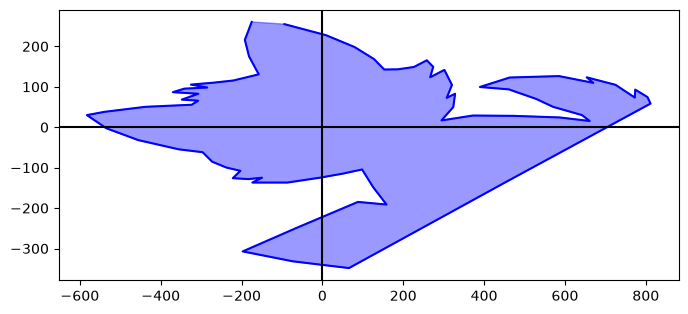

[[ 0.78798298 -0.20164098]
 [ 1.27635529  1.00590304]]


In [10]:
rot_lynx, M_rot = rotation(lynx, 45)
s_lynx, M_str = stretch(rot_lynx, 1.5, 0.7)
lynx_combination3, M_shr = shear(s_lynx, 0.5, 0)

display(lynx_combination3)
print(M_rot @ M_str @ M_shr)

yes, the final output depends on the order of transformations

task3


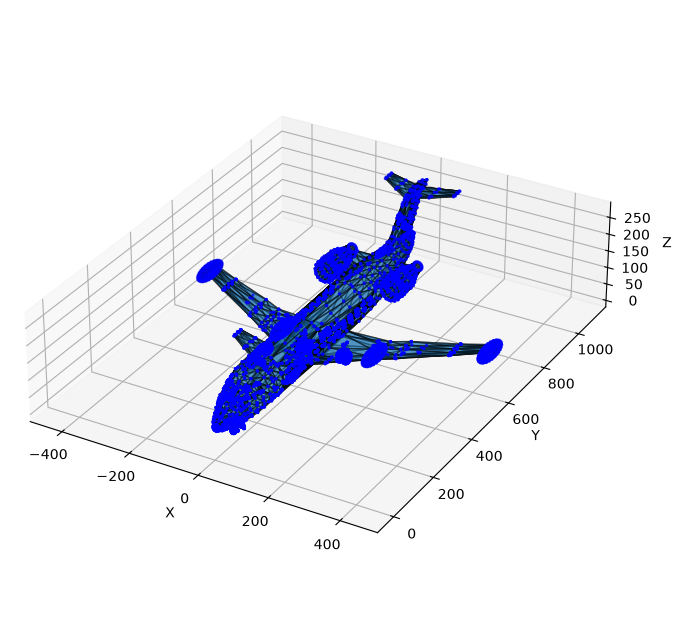

In [11]:
vertices, faces = read_off('airplane_0627.off')
plot_off(vertices, faces)

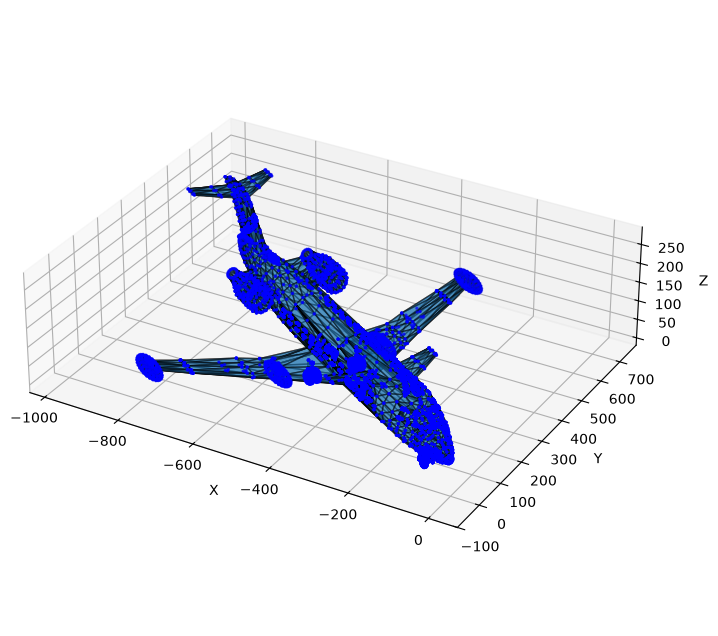

[[ 0.52532199 -0.85090352  0.        ]
 [ 0.85090352  0.52532199  0.        ]
 [ 0.          0.          1.        ]]


In [12]:
xy_rotated_vertices, M_rot = rotate_xy(vertices, 45)
plot_off(xy_rotated_vertices, faces)
print(M_rot)

task 4


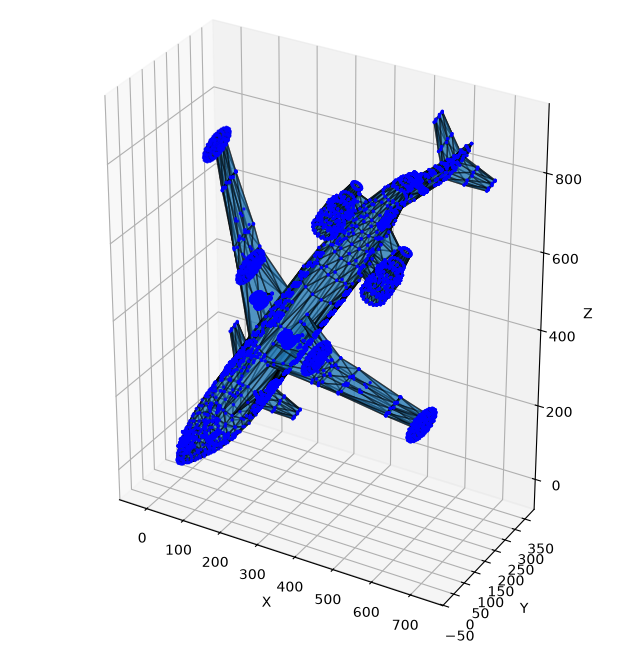

[[ 0.6824845  -0.56005074 -0.46963611]
 [-0.51903474  0.08103168 -0.85090352]
 [ 0.51460455  0.82448592 -0.23538292]]


In [13]:
v1, M_xz = rotate_xz(vertices, 90)
v2, M_yz = rotate_yz(v1, 45)
rotated_vertices, M_xy = rotate_xy(v2, 30)

plot_off(rotated_vertices, faces)
print(M_xz @ M_yz @ M_xy)